# Milestone 1 – Phase 1
## Exploratory Data Analysis (EDA)

This notebook presents the exploratory data analysis of the three preprocessed datasets submitted during Week 3:

1. Demographics
2. Social Media Interactions
3. Transactions

The analysis examines the datasets' structure, statistical properties, distributions, patterns, anomalies, relationships, and observations relevant to future machine learning activities.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
demographics = pd.read_csv("datasets/demographics_clean.csv")
social = pd.read_csv("datasets/social_clean.csv")
transactions = pd.read_csv("datasets/transactions_clean.csv")

print("All 3 datasets loaded successfully!")

All 3 datasets loaded successfully!


## 1. Dataset Structure

This section examines the structure of the three preprocessed datasets by reviewing their dimensions, initial records, and variables.

In [3]:
print("Demographics:", demographics.shape)
print("Social:", social.shape)
print("Transactions:", transactions.shape)

Demographics: (3023, 6)
Social: (3020, 6)
Transactions: (3015, 7)


In [4]:
print("===== DEMOGRAPHICS =====")
display(demographics.head())

print("===== SOCIAL MEDIA =====")
display(social.head())

print("===== TRANSACTIONS =====")
display(transactions.head())

===== DEMOGRAPHICS =====


,CustomerID,Age,Gender,Location,IncomeLevel,SignupDate
0,9207fa75-5758-48d1-94ad-19c041e0520f,51.0,Female,Jensenberg,Low,2022-11-17
1,5fb09cd8-a473-46f7-80bd-6e49cf509078,NaN,Female,Castilloport,High,2020-07-21
2,c139496e-cc89-498a-bd90-1fb4627b6cff,37.0,Male,Lake Jennifertown,NaN,2021-01-01
3,50118139-7264-428f-81cc-a25fddc5d6dd,44.0,Male,Port Carl,Medium,2024-10-06
4,7d1f2bbc-8d16-4fbc-9b37-ece3324e8ed4,50.0,Female,Jessebury,High,2023-08-24


===== SOCIAL MEDIA =====


,CustomerID,InteractionID,InteractionDate,Platform,InteractionType,Sentiment
0,2dcb9523-356b-40b2-a67b-1f27797de261,e5d15761-d0a7-4329-89e3-79a892c56097,2023-11-07,Unknown,Comment,Unknown
1,e12c37b3-7d4d-472f-9fd8-0df2cb3001aa,02f9f376-70ae-4fcd-9070-1db977939948,2023-06-07,Twitter,Share,Unknown
2,08a911a3-65e6-4f5d-a6a1-ae7ddcbe28a2,a83fa04c-f109-4f24-8ce1-2078154f6a1c,2024-05-24,Instagram,Comment,Neutral
3,efdfdfc9-5dbb-4478-911a-101a390a0285,28a69c4b-a2e4-4c74-a130-1132d7733fdf,2023-01-11,Instagram,Like,Neutral
4,ca1e90f6-0e5f-492e-ab92-252ff540da18,d9d1c6f8-5e15-4738-b52b-13c2982420cc,2023-08-07,Instagram,Like,Unknown


===== TRANSACTIONS =====


,CustomerID,TransactionID,TransactionDate,Amount,ProductCategory,PaymentMethod,Amount_Clean
0,60567026-f719-4cd6-849e-137e86d8938f,5ff75116-0a50-4d04-80fb-31e5ccbb0769,2024-05-15,117.64,Clothing,PayPal,117.64
1,4090ba85-b111-4f75-a792-c777965f5255,2c39b9fe-ff57-4d39-9321-9f5cdf187aa1,2023-04-26,466.14,Health & Beauty,Bank Transfer,466.14
2,9223891b-73ff-4d5c-b8ae-13ece82ee28b,f79588dd-3db9-4ffa-97f8-7de0e64259f1,2022-09-23,563.99,Clothing,Debit Card,563.99
3,9243eebc-938f-480c-8564-16d503d250de,401c0fc9-60df-4455-ad78-67c132f9897d,2024-04-15,254.44,Automotive,PayPal,254.44
4,6e3e8eb8-bc0f-4ffe-9f74-5d5efec9502f,2034aebc-8280-4254-a667-92bcd1c2be4f,2024-03-06,590.52,Home & Garden,Bank Transfer,590.52


In [5]:
print("===== DEMOGRAPHICS DATA TYPES =====")
print(demographics.dtypes)

print("\n===== SOCIAL MEDIA DATA TYPES =====")
print(social.dtypes)

print("\n===== TRANSACTIONS DATA TYPES =====")
print(transactions.dtypes)

===== DEMOGRAPHICS DATA TYPES =====
CustomerID      object
Age            float64
Gender          object
Location        object
IncomeLevel     object
SignupDate      object
dtype: object

===== SOCIAL MEDIA DATA TYPES =====
CustomerID         object
InteractionID      object
InteractionDate    object
Platform           object
InteractionType    object
Sentiment          object
dtype: object

===== TRANSACTIONS DATA TYPES =====
CustomerID          object
TransactionID       object
TransactionDate     object
Amount              object
ProductCategory     object
PaymentMethod       object
Amount_Clean       float64
dtype: object


## 2. Data Quality Check

This section examines the datasets for missing values and duplicate records. Identifying incomplete or duplicated observations is important because these issues may affect statistical analysis and future machine learning activities.

In [6]:
print("===== DEMOGRAPHICS: MISSING VALUES =====")
print(demographics.isnull().sum())

print("\n===== SOCIAL MEDIA: MISSING VALUES =====")
print(social.isnull().sum())

print("\n===== TRANSACTIONS: MISSING VALUES =====")
print(transactions.isnull().sum())

===== DEMOGRAPHICS: MISSING VALUES =====
CustomerID       0
Age            310
Gender           0
Location         0
IncomeLevel    285
SignupDate       0
dtype: int64

===== SOCIAL MEDIA: MISSING VALUES =====
CustomerID         0
InteractionID      0
InteractionDate    0
Platform           0
InteractionType    0
Sentiment          0
dtype: int64

===== TRANSACTIONS: MISSING VALUES =====
CustomerID           0
TransactionID        0
TransactionDate      0
Amount             283
ProductCategory    282
PaymentMethod        0
Amount_Clean       313
dtype: int64


In [7]:
print("===== DUPLICATE ROWS =====")

print("Demographics duplicates:", demographics.duplicated().sum())
print("Social Media duplicates:", social.duplicated().sum())
print("Transactions duplicates:", transactions.duplicated().sum())

===== DUPLICATE ROWS =====
Demographics duplicates: 0
Social Media duplicates: 0
Transactions duplicates: 0


## 3. Descriptive Statistics

This section calculates measures of central tendency and variability for the numerical variables in the preprocessed datasets. The measures include mean, median, mode, minimum, maximum, range, standard deviation, and variance.

In [8]:
print("===== AGE DESCRIPTIVE STATISTICS =====")

age = demographics["Age"]

print("Mean:", age.mean())
print("Median:", age.median())
print("Mode:", age.mode().tolist())
print("Minimum:", age.min())
print("Maximum:", age.max())
print("Range:", age.max() - age.min())
print("Standard Deviation:", age.std())
print("Variance:", age.var())

===== AGE DESCRIPTIVE STATISTICS =====
Mean: 45.42167342425359
Median: 45.0
Mode: [62.0]
Minimum: -1.0
Maximum: 150.0
Range: 151.0
Standard Deviation: 19.73135957653303
Variance: 389.3265507384417


In [9]:
print("===== TRANSACTION AMOUNT DESCRIPTIVE STATISTICS =====")

amount = transactions["Amount_Clean"]

print("Mean:", amount.mean())
print("Median:", amount.median())
print("Mode:", amount.mode().tolist())
print("Minimum:", amount.min())
print("Maximum:", amount.max())
print("Range:", amount.max() - amount.min())
print("Standard Deviation:", amount.std())
print("Variance:", amount.var())

===== TRANSACTION AMOUNT DESCRIPTIVE STATISTICS =====
Mean: 489.78891931902285
Median: 496.625
Mode: [-100.0]
Minimum: -100.0
Maximum: 999.86
Range: 1099.8600000000001
Standard Deviation: 299.23945275299394
Variance: 89544.25008391129


## 4. Categorical Variable Analysis

Frequency distributions are examined for the categorical variables in each dataset to identify common categories, less frequent categories, and possible imbalances in the data.

In [10]:
print("===== GENDER =====")
print(demographics["Gender"].value_counts(dropna=False))

print("\n===== INCOME LEVEL =====")
print(demographics["IncomeLevel"].value_counts(dropna=False))

print("\n===== LOCATION =====")
print(demographics["Location"].value_counts(dropna=False).head(15))

===== GENDER =====
Gender
Female    1528
Male      1495
Name: count, dtype: int64

===== INCOME LEVEL =====
IncomeLevel
High      946
Low       923
Medium    869
NaN       285
Name: count, dtype: int64

===== LOCATION =====
Location
Port Michael         5
Michaelville         4
Port Eric            4
Michaelton           4
West David           4
West Michael         4
New Michael          4
West Robert          4
North Jennifer       4
Brownland            3
North Christopher    3
Port William         3
Brownbury            3
Kimberlyview         3
East Brittany        3
Name: count, dtype: int64


In [11]:
print("===== PLATFORM =====")
print(social["Platform"].value_counts(dropna=False))

print("\n===== INTERACTION TYPE =====")
print(social["InteractionType"].value_counts(dropna=False))

print("\n===== SENTIMENT =====")
print(social["Sentiment"].value_counts(dropna=False))

===== PLATFORM =====
Platform
Instagram    921
Twitter      917
Facebook     891
Unknown      291
Name: count, dtype: int64

===== INTERACTION TYPE =====
InteractionType
Comment    1018
Share      1007
Like        995
Name: count, dtype: int64

===== SENTIMENT =====
Sentiment
Positive         905
Neutral          874
Negative         866
Unknown          309
Very Negative     34
Very Positive     32
Name: count, dtype: int64


In [12]:
print("===== PRODUCT CATEGORY =====")
print(transactions["ProductCategory"].value_counts(dropna=False))

print("\n===== PAYMENT METHOD =====")
print(transactions["PaymentMethod"].value_counts(dropna=False))

===== PRODUCT CATEGORY =====
ProductCategory
Clothing           571
Electronics        564
Automotive         540
Home & Garden      530
Health & Beauty    528
NaN                282
Name: count, dtype: int64

===== PAYMENT METHOD =====
PaymentMethod
Debit Card       767
Credit Card      755
PayPal           750
Bank Transfer    743
Name: count, dtype: int64


In [13]:
print("===== UNUSUAL AGE VALUES =====")

print(
    demographics[
        (demographics["Age"] < 0) |
        (demographics["Age"] > 100)
    ][
        ["CustomerID", "Age", "Gender", "Location", "IncomeLevel"]
    ]
)

===== UNUSUAL AGE VALUES =====
                                CustomerID    Age  Gender          Location  \
10    c96a5ee9-f1a6-416a-adc6-1c8b128c7399  150.0    Male        Hansontown   
48    b1d6a46b-214c-4592-9688-82d0fd977bb2  150.0  Female  North Cindyhaven   
64    52303d17-9d24-4c20-89e3-7bcfa92140c9  150.0    Male      Spencermouth   
72    7a461a97-18fd-4686-ab3f-adaded72069d  150.0    Male          Pageside   
99    5ba7a03b-0d2f-4fc3-bd36-7a675c1ac61e  150.0  Female  East Ryanchester   
...                                    ...    ...     ...               ...   
2916  730f04f4-652c-4eb0-ab28-4e63ca84e166   -1.0  Female        Meganhaven   
2975  ba3f79ad-b3ab-47e5-8803-22cb4ea8cf13  150.0  Female     Rodriguezside   
3000  3814b8e4-cade-4665-86af-dda3e3628f17  150.0  Female  Port Bonnieshire   
3012  6b2f8f03-ab9e-48a6-a07e-10e794b04fe0   -1.0    Male        Lake Karen   
3013  7544489f-ec7e-48af-bec6-b6eab94a6e5c  150.0    Male       South Jared   

     IncomeLevel  
1

### Age Anomalies

The age variable contains 63 potentially anomalous records with values below 0 or above 100. The values of -1 represent invalid age entries, while values of 150 are unusually high. These observations may influence descriptive statistics and should be investigated before being used for future machine learning activities. No values are removed or modified during this exploratory analysis.

In [14]:
print("===== UNUSUAL TRANSACTION AMOUNTS =====")

print(
    transactions[
        transactions["Amount_Clean"] <= 0
    ][
        [
            "TransactionID",
            "Amount",
            "Amount_Clean",
            "ProductCategory",
            "PaymentMethod"
        ]
    ]
)

===== UNUSUAL TRANSACTION AMOUNTS =====
                             TransactionID Amount  Amount_Clean  \
134   793af848-8138-40e7-929c-67254ea56ca7      0           0.0   
196   a6b7182d-6c74-4fa5-9491-035e49e5eb87      0           0.0   
274   814d25d8-690b-45bb-96c9-b7a3e92a61db   -100        -100.0   
308   c0ea759c-a09f-4989-bc3b-f56a0c0400d8      0           0.0   
319   fb908e24-4c1e-4e24-a1b0-62465fa0515c   -100        -100.0   
...                                    ...    ...           ...   
3004  5f93f1dc-0363-4e69-979b-f5d58fd42658   -100        -100.0   
3005  2e0b66a9-af5d-4cf9-bb60-55ab2932edee   -100        -100.0   
3009  5fca256b-cd5a-48fa-8b07-37f39adde8c9   -100        -100.0   
3013  185ee140-348a-4461-bd40-07a7e8535815      0           0.0   
3014  c751a808-ed8d-44d0-8c52-8253ad564c9a   -100        -100.0   

      ProductCategory  PaymentMethod  
134     Home & Garden         PayPal  
196       Electronics  Bank Transfer  
274               NaN         PayPal  

### Transaction Amount Anomalies

The transaction data contains 70 records with Amount_Clean values less than or equal to zero. These include zero-value transactions and negative transaction amounts of -100. Such values may represent unusual or potentially invalid transactions and can affect descriptive statistics. These records are retained for the exploratory analysis but should be investigated before being used for future machine learning activities.

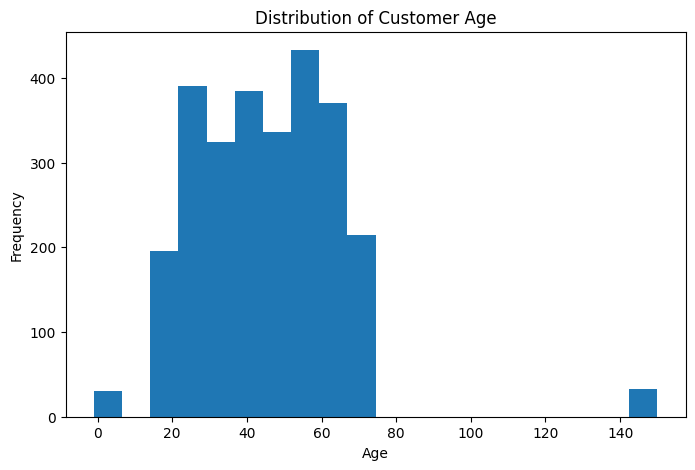

In [15]:
plt.figure(figsize=(8, 5))

plt.hist(demographics["Age"].dropna(), bins=20)

plt.title("Distribution of Customer Age")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

### Age Distribution Interpretation

The histogram shows that most customer ages are concentrated between approximately 15 and 70 years old, with the highest frequencies occurring in the middle of this range. The distribution also shows unusual values near 0 and 150, which correspond to the previously identified -1 and 150 age values. These anomalies may influence the overall distribution and descriptive statistics.

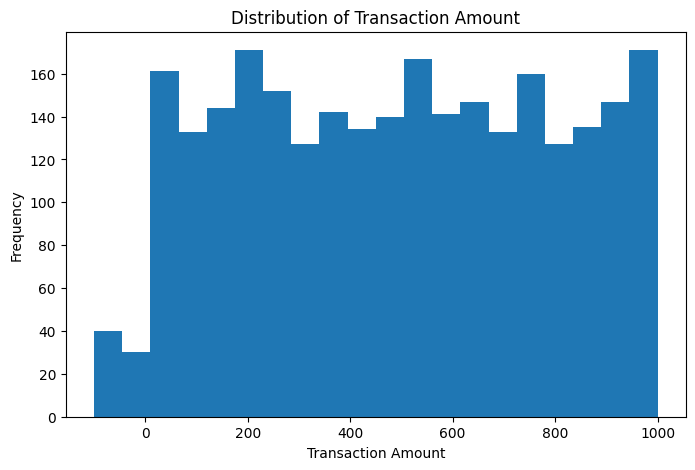

In [16]:
plt.figure(figsize=(8, 5))

plt.hist(transactions["Amount_Clean"].dropna(), bins=20)

plt.title("Distribution of Transaction Amount")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")

plt.show()

### Transaction Amount Distribution Interpretation

The histogram shows that transaction amounts are broadly distributed across the observed range, with values extending from negative amounts to approximately 1,000. The distribution does not show a strong concentration in a single range. Negative and zero values are also present, consistent with the transaction anomalies identified earlier. These unusual values should be considered when interpreting the descriptive statistics and before using the data for future machine learning activities.

In [17]:
age_transactions = pd.merge(
    demographics[["CustomerID", "Age"]],
    transactions[["CustomerID", "Amount_Clean"]],
    on="CustomerID",
    how="inner"
)

print("Combined Age and Transaction dataset:")
print(age_transactions.shape)

display(age_transactions.head())

Combined Age and Transaction dataset:
(3045, 3)


,CustomerID,Age,Amount_Clean
0,9207fa75-5758-48d1-94ad-19c041e0520f,51.0,NaN
1,9207fa75-5758-48d1-94ad-19c041e0520f,51.0,660.87
2,5fb09cd8-a473-46f7-80bd-6e49cf509078,NaN,976.88
3,c139496e-cc89-498a-bd90-1fb4627b6cff,37.0,528.32
4,7d1f2bbc-8d16-4fbc-9b37-ece3324e8ed4,50.0,733.46


In [18]:
age_amount = age_transactions.dropna(
    subset=["Age", "Amount_Clean"]
)

print("Rows available for Age vs Transaction Amount:")
print(age_amount.shape)

display(age_amount.head())

Rows available for Age vs Transaction Amount:
(2451, 3)


,CustomerID,Age,Amount_Clean
1,9207fa75-5758-48d1-94ad-19c041e0520f,51.0,660.87
3,c139496e-cc89-498a-bd90-1fb4627b6cff,37.0,528.32
4,7d1f2bbc-8d16-4fbc-9b37-ece3324e8ed4,50.0,733.46
6,2de49c7c-32ae-4ba8-b058-622a090d7094,53.0,276.46
7,2de49c7c-32ae-4ba8-b058-622a090d7094,53.0,615.28


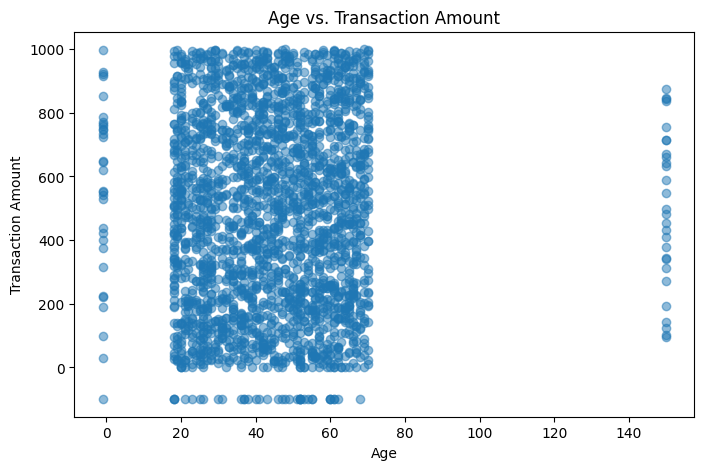

In [19]:
plt.figure(figsize=(8, 5))

plt.scatter(
    age_amount["Age"],
    age_amount["Amount_Clean"],
    alpha=0.5
)

plt.title("Age vs. Transaction Amount")
plt.xlabel("Age")
plt.ylabel("Transaction Amount")

plt.show()

In [20]:
correlation = age_amount["Age"].corr(age_amount["Amount_Clean"])

print("Correlation between Age and Transaction Amount:", correlation)

Correlation between Age and Transaction Amount: 0.020932986760669778


### Age and Transaction Amount Relationship

The correlation between customer age and transaction amount is approximately 0.021. This value is very close to zero, indicating little to no linear relationship between the two variables in the analyzed data. The scatter plot also shows that transaction amounts are widely distributed across the observed age range rather than following a clear upward or downward pattern. This suggests that age alone may not be a strong linear indicator of transaction amount in this dataset.

In [21]:
summary = pd.DataFrame({
    "Statistic": [
        "Mean",
        "Median",
        "Mode",
        "Minimum",
        "Maximum",
        "Range",
        "Standard Deviation",
        "Variance"
    ],
    "Age": [
        demographics["Age"].mean(),
        demographics["Age"].median(),
        demographics["Age"].mode().iloc[0],
        demographics["Age"].min(),
        demographics["Age"].max(),
        demographics["Age"].max() - demographics["Age"].min(),
        demographics["Age"].std(),
        demographics["Age"].var()
    ],
    "Transaction Amount": [
        transactions["Amount_Clean"].mean(),
        transactions["Amount_Clean"].median(),
        transactions["Amount_Clean"].mode().iloc[0],
        transactions["Amount_Clean"].min(),
        transactions["Amount_Clean"].max(),
        transactions["Amount_Clean"].max() - transactions["Amount_Clean"].min(),
        transactions["Amount_Clean"].std(),
        transactions["Amount_Clean"].var()
    ]
})

summary

,Statistic,Age,Transaction Amount
0,Mean,45.421673,489.788919
1,Median,45.000000,496.625000
2,Mode,62.000000,-100.000000
3,Minimum,-1.000000,-100.000000
4,Maximum,150.000000,999.860000
5,Range,151.000000,1099.860000
6,Standard Deviation,19.731360,299.239453
7,Variance,389.326551,89544.250084


### Descriptive Statistics Interpretation

The descriptive statistics show that the average customer age is approximately 45.42 years, while the median age is 45 years. The mean and median are close, suggesting that the central values are relatively similar. However, the minimum age of -1 and maximum age of 150 indicate unusual values that may affect the results.

For transaction amounts, the mean is approximately 489.79, while the median is 496.63. The transaction amounts have a wide range from -100 to 999.86, with a standard deviation of approximately 299.24. The negative value of -100 appears as both the mode and minimum, indicating an unusual transaction value that should be investigated before future machine learning activities.

Overall, the descriptive statistics provide a summary of the distribution and variability of the numerical variables and highlight values that may require further attention.

## 5. Overall EDA Findings and Observations

The exploratory analysis identified several important patterns and data quality observations across the three datasets.

- The demographics dataset contains 3,023 records, the social media dataset contains 3,020 records, and the transactions dataset contains 3,015 records.
- Gender is relatively balanced between Female and Male customers.
- Income levels are distributed across High, Medium, and Low categories, although some income values are missing.
- Social media platforms and interaction types are relatively balanced. However, some platform and sentiment values are recorded as Unknown.
- Product categories and payment methods in the transaction dataset are also relatively balanced.
- The age variable contains unusual values, including -1 and 150, which may affect statistical analysis.
- The transaction amount variable contains zero and negative values, including -100, which may represent unusual or potentially invalid transactions.
- The correlation between Age and Transaction Amount is approximately 0.021, indicating little to no linear relationship between these two variables in the analyzed data.
- These findings highlight variables and records that may require further investigation or preprocessing before being used in future machine learning activities.

## 6. Conclusion

The exploratory data analysis provided an overview of the three preprocessed datasets and their main characteristics. Descriptive statistics, frequency distributions, visualizations, anomaly checks, and variable relationships were examined.

The analysis identified several useful patterns as well as data quality concerns, particularly unusual age values, negative or zero transaction amounts, and missing values in some variables. The relationship analysis also showed very little linear correlation between customer age and transaction amount.

These findings provide a foundation for understanding the datasets and identifying variables that may require further attention during future machine learning activities.